In [ ]:


import pandas as pd

df = pd.read_excel("/content/drive/MyDrive/AML file/Online Retail.xlsx")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (541909, 8)

First 5 Rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:

# Hinglish: Revenue calculate karke sales, customers aur suspicious transactions ka initial audit kar rahe hain.

df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print("Total Rows:", len(df))
print("Unique Invoices:", df["InvoiceNo"].nunique())
print("Unique Products:", df["StockCode"].nunique())
print("Unique Customers:", df["CustomerID"].nunique())

print("\nNegative Quantity Rows:", (df["Quantity"] < 0).sum())
print("Zero Quantity Rows:", (df["Quantity"] == 0).sum())
print("Non-positive Unit Price Rows:", (df["UnitPrice"] <= 0).sum())

print(
    "Cancelled Invoice Rows:",
    df["InvoiceNo"].astype(str).str.startswith("C").sum()
)

print("\nTotal Revenue (including all records):", df["Revenue"].sum())


Total Rows: 541909
Unique Invoices: 25900
Unique Products: 4070
Unique Customers: 4372

Negative Quantity Rows: 10624
Zero Quantity Rows: 0
Non-positive Unit Price Rows: 2517
Cancelled Invoice Rows: 9288

Total Revenue (including all records): 9747747.934


In [ ]:

# Hinglish: Negative quantity, cancelled invoices aur unusual prices ke beech relation check kar rahe hain.

cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
negative_qty = df["Quantity"] < 0
non_positive_price = df["UnitPrice"] <= 0

print("Negative quantity AND cancelled invoice:",
      (negative_qty & cancelled).sum())

print("Negative quantity WITHOUT cancelled invoice:",
      (negative_qty & ~cancelled).sum())

print("Non-positive price AND negative quantity:",
      (non_positive_price & negative_qty).sum())

print("\nNon-positive price examples:")
print(
    df.loc[
        non_positive_price,
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "CustomerID"]
    ].head(10).to_string(index=False)
)

print("\nNegative quantity examples:")
print(
    df.loc[
        negative_qty,
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "CustomerID"]
    ].head(10).to_string(index=False)
)


Negative quantity AND cancelled invoice: 9288
Negative quantity WITHOUT cancelled invoice: 1336
Non-positive price AND negative quantity: 1336

Non-positive price examples:
InvoiceNo StockCode Description  Quantity  UnitPrice  CustomerID
   536414     22139         NaN        56        0.0         NaN
   536545     21134         NaN         1        0.0         NaN
   536546     22145         NaN         1        0.0         NaN
   536547     37509         NaN         1        0.0         NaN
   536549    85226A         NaN         1        0.0         NaN
   536550     85044         NaN         1        0.0         NaN
   536552     20950         NaN         1        0.0         NaN
   536553     37461         NaN         3        0.0         NaN
   536554     84670         NaN        23        0.0         NaN
   536589     21777         NaN       -10        0.0         NaN

Negative quantity examples:
InvoiceNo StockCode                       Description  Quantity  UnitPrice  Custome

In [ ]:

# Hinglish: Zero ya negative price wali rows mein quantity ka pattern count kar rahe hain.

print("Negative quantity:",
      (df.loc[df["UnitPrice"] <= 0, "Quantity"] < 0).sum())

print("Positive quantity:",
      (df.loc[df["UnitPrice"] <= 0, "Quantity"] > 0).sum())


Negative quantity: 1336
Positive quantity: 1181


In [ ]:

# Hinglish: Zero price aur negative price wali rows alag-alag count kar rahe hain.

print("Zero price rows:", (df["UnitPrice"] == 0).sum())
print("Negative price rows:", (df["UnitPrice"] < 0).sum())


Zero price rows: 2515
Negative price rows: 2


In [ ]:

# Hinglish: Zero-price records mein missing Description aur CustomerID count kar rahe hain.

zero_price = df[df["UnitPrice"] == 0]

print("Zero-price rows:", len(zero_price))
print("Missing Description:", zero_price["Description"].isna().sum())
print("Missing CustomerID:", zero_price["CustomerID"].isna().sum())


Zero-price rows: 2515
Missing Description: 1454
Missing CustomerID: 2475


In [ ]:

# Hinglish: Valid positive sales records se monthly revenue nikal kar interactive chart bana rahe hain.

import pandas as pd
import plotly.express as px

sales = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()

sales["InvoiceDate"] = pd.to_datetime(sales["InvoiceDate"])
sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]

monthly_sales = (
    sales.groupby(sales["InvoiceDate"].dt.to_period("M"))["Revenue"]
    .sum()
    .reset_index()
)

monthly_sales["InvoiceDate"] = monthly_sales["InvoiceDate"].astype(str)

fig = px.line(
    monthly_sales,
    x="InvoiceDate",
    y="Revenue",
    markers=True,
    title="Monthly Retail Revenue Trend",
    labels={
        "InvoiceDate": "Month",
        "Revenue": "Revenue"
    }
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Month",
    yaxis_title="Revenue",
    hovermode="x unified"
)

fig.show()


In [ ]:

# Hinglish: Sabse zyada aur sabse kam monthly revenue wale months identify kar rahe hain.

best_month = monthly_sales.loc[monthly_sales["Revenue"].idxmax()]
worst_month = monthly_sales.loc[monthly_sales["Revenue"].idxmin()]

print("Highest Revenue Month:", best_month["InvoiceDate"])
print("Revenue:", round(best_month["Revenue"], 2))

print("\nLowest Revenue Month:", worst_month["InvoiceDate"])
print("Revenue:", round(worst_month["Revenue"], 2))


Highest Revenue Month: 2011-11
Revenue: 1509496.33

Lowest Revenue Month: 2011-02
Revenue: 523631.89


In [ ]:

# Hinglish: Har month ki sold quantity aur unique invoices compare kar rahe hain.

monthly_metrics = (
    sales.groupby(sales["InvoiceDate"].dt.to_period("M"))
    .agg(
        Total_Quantity=("Quantity", "sum"),
        Unique_Invoices=("InvoiceNo", "nunique"),
        Revenue=("Revenue", "sum")
    )
    .reset_index()
)

monthly_metrics["InvoiceDate"] = monthly_metrics["InvoiceDate"].astype(str)

print(
    monthly_metrics[
        monthly_metrics["InvoiceDate"].isin(["2011-02", "2011-11"])
    ].to_string(index=False)
)


InvoiceDate  Total_Quantity  Unique_Invoices    Revenue
    2011-02          283555             1100  523631.89
    2011-11          754507             2769 1509496.33


In [ ]:

# Hinglish: Har customer ka total purchase revenue calculate karke top 10 customers nikal rahe hain.

customer_revenue = (
    sales.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Orders=("InvoiceNo", "nunique"),
        Total_Items=("Quantity", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
    .head(10)
    .reset_index()
)

print(customer_revenue.to_string(index=False))


 CustomerID  Total_Revenue  Total_Orders  Total_Items
    14646.0      280206.02            73       196915
    18102.0      259657.30            60        64124
    17450.0      194550.79            46        69993
    16446.0      168472.50             2        80997
    14911.0      143825.06           201        80265
    12415.0      124914.53            21        77374
    14156.0      117379.63            55        57885
    17511.0       91062.38            31        64549
    16029.0       81024.84            63        40208
    12346.0       77183.60             1        74215


In [ ]:
# Recency: Customer ne last purchase kab ki?
# Frequency: Customer ne kitni baar purchase kiya?
# Monetary: Customer ne total kitna spend kiya?
# Hinglish: Cancelled orders aur invalid transactions remove karke RFM metrics calculate karna

rfm_data = df.dropna(subset=['CustomerID']).copy()

rfm_data['InvoiceDate'] = pd.to_datetime(rfm_data['InvoiceDate'])

rfm_data = rfm_data[
    (~rfm_data['InvoiceNo'].astype(str).str.startswith('C')) &
    (rfm_data['Quantity'] > 0) &
    (rfm_data['UnitPrice'] > 0)
]

rfm_data['Revenue'] = rfm_data['Quantity'] * rfm_data['UnitPrice']

snapshot_date = rfm_data['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = rfm_data.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum')
).reset_index()

rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [ ]:
# Hinglish: Customers ko Recency, Frequency aur Monetary ke basis par 1-5 score dena

rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm.head(10)

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,12346.0,326,1,77183.60,1,1,5
1,12347.0,2,7,4310.00,5,5,5
2,12348.0,75,4,1797.24,2,4,4
3,12349.0,19,1,1757.55,4,1,4
4,12350.0,310,1,334.40,1,1,2
5,12352.0,36,8,2506.04,3,5,5
6,12353.0,204,1,89.00,1,1,1
7,12354.0,232,1,1079.40,1,1,4
8,12355.0,214,1,459.40,1,1,2
9,12356.0,23,3,2811.43,4,3,5


In [ ]:
# Hinglish: RFM scores ke basis par customer segments identify karna

rfm['RFM_Score'] = rfm['R_Score'] + rfm['F_Score'] + rfm['M_Score']

rfm['Segment'] = pd.cut(
    rfm['RFM_Score'],
    bins=[2, 5, 8, 11, 13, 15],
    labels=['Hibernating', 'At Risk', 'Potential Loyalist', 'Loyal', 'Champions']
)

rfm.head(10)

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346.0,326,1,77183.60,1,1,5,7,At Risk
1,12347.0,2,7,4310.00,5,5,5,15,Champions
2,12348.0,75,4,1797.24,2,4,4,10,Potential Loyalist
3,12349.0,19,1,1757.55,4,1,4,9,Potential Loyalist
4,12350.0,310,1,334.40,1,1,2,4,Hibernating
5,12352.0,36,8,2506.04,3,5,5,13,Loyal
6,12353.0,204,1,89.00,1,1,1,3,Hibernating
7,12354.0,232,1,1079.40,1,1,4,6,At Risk
8,12355.0,214,1,459.40,1,1,2,4,Hibernating
9,12356.0,23,3,2811.43,4,3,5,12,Loyal


In [ ]:
# Hinglish: Har customer segment ka size aur revenue calculate karna

segment_analysis = rfm.groupby('Segment', observed=True).agg(
    Customers=('CustomerID', 'count'),
    Total_Revenue=('Monetary', 'sum')
).reset_index()

segment_analysis

,Segment,Customers,Total_Revenue
0,Hibernating,887,203857.560
1,At Risk,1188,691993.773
2,Potential Loyalist,1019,1206307.361
3,Loyal,602,1590625.370
4,Champions,642,5218623.840


In [ ]:
# Hinglish: Har customer segment ka total revenue mein contribution calculate karna

segment_analysis['Revenue_%'] = (
    segment_analysis['Total_Revenue'] /
    segment_analysis['Total_Revenue'].sum()
) * 100

segment_analysis

,Segment,Customers,Total_Revenue,Revenue_%
0,Hibernating,887,203857.560,2.287602
1,At Risk,1188,691993.773,7.765258
2,Potential Loyalist,1019,1206307.361,13.536664
3,Loyal,602,1590625.370,17.849316
4,Champions,642,5218623.840,58.561160


In [ ]:
# Hinglish: At Risk customers mein highest spending wale top 10 customers nikalna

at_risk_top10 = rfm[rfm['Segment'] == 'At Risk'].nlargest(10, 'Monetary')

at_risk_top10[['CustomerID', 'Recency', 'Frequency', 'Monetary']]

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.600
196,12590.0,211,2,9864.260
278,12688.0,114,1,4873.810
329,12752.0,81,1,4366.780
27,12378.0,130,1,4008.620
332,12755.0,281,2,3811.950
1185,13952.0,218,2,3251.071
597,13135.0,197,1,3096.000
227,12625.0,212,2,2683.820
1533,14439.0,320,1,2661.240


In [ ]:
# Hinglish: Customer 12346 ki purchase transaction details check karna

rfm_data[rfm_data['CustomerID'] == 12346][
    ['InvoiceNo', 'InvoiceDate', 'Quantity', 'UnitPrice', 'Revenue']
]

,InvoiceNo,InvoiceDate,Quantity,UnitPrice,Revenue
61619,541431,2011-01-18 10:01:00,74215,1.04,77183.6


In [ ]:
# Hinglish: Har customer segment ka average buying behaviour compare karna

rfm.groupby('Segment', observed=True).agg(
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Spending=('Monetary', 'mean')
).round(2)

,Avg_Recency,Avg_Frequency,Avg_Spending
Segment,,,
Hibernating,224.17,1.05,229.83
At Risk,102.68,1.63,582.49
Potential Loyalist,55.91,3.17,1183.81
Loyal,28.44,5.63,2642.23
Champions,10.13,14.09,8128.70


In [ ]:
# Hinglish: Invoice-wise revenue calculate karke unusually high transactions identify karna

invoice_data = rfm_data.groupby('InvoiceNo').agg(
    CustomerID=('CustomerID', 'first'),
    Revenue=('Revenue', 'sum')
).reset_index()

Q1 = invoice_data['Revenue'].quantile(0.25)
Q3 = invoice_data['Revenue'].quantile(0.75)
IQR = Q3 - Q1

anomalies = invoice_data[invoice_data['Revenue'] > Q3 + 1.5 * IQR]

anomalies.sort_values('Revenue', ascending=False).head(10)

,InvoiceNo,CustomerID,Revenue
18499,581483,16446.0,168469.60
1909,541431,12346.0,77183.60
7925,556444,15098.0,38970.00
12417,567423,17450.0,31698.16
8111,556917,12415.0,22775.93
14456,572209,18102.0,22206.00
12409,567381,17450.0,22104.80
10842,563614,12415.0,21880.44
5462,550461,15749.0,21535.90
14368,572035,14646.0,20277.92


In [ ]:
# Customer 16446 ki puri history nikalna (cancelled invoices ke saath, raw df se)

c = df[df['CustomerID'] == 16446].copy()          # sirf customer 16446 ke rows
c['InvoiceDate'] = pd.to_datetime(c['InvoiceDate'])  # date ko datetime banao
c['Revenue'] = c['Quantity'] * c['UnitPrice']     # har line ka revenue
c = c.sort_values('InvoiceDate')                  # time ke order mein

print("Total rows:", len(c))
print("Cancelled rows:", c['InvoiceNo'].astype(str).str.startswith('C').sum())
print(c[['InvoiceNo','InvoiceDate','StockCode','Description','Quantity','UnitPrice','Revenue']].to_string(index=False))

Total rows: 4
Cancelled rows: 1
InvoiceNo         InvoiceDate StockCode                 Description  Quantity  UnitPrice    Revenue
   553573 2011-05-18 09:52:00     22980      PANTRY SCRUBBING BRUSH         1       1.65       1.65
   553573 2011-05-18 09:52:00     22982         PANTRY PASTRY BRUSH         1       1.25       1.25
   581483 2011-12-09 09:15:00     23843 PAPER CRAFT , LITTLE BIRDIE     80995       2.08  168469.60
  C581484 2011-12-09 09:27:00     23843 PAPER CRAFT , LITTLE BIRDIE    -80995       2.08 -168469.60


In [ ]:
# Kisi bhi customer ki history dekhne ke liye reusable function (cancelled invoices ke saath)

def customer_history(cust_id):
    t = df[df['CustomerID'] == cust_id].copy()           # sirf us customer ke rows
    t['InvoiceDate'] = pd.to_datetime(t['InvoiceDate'])  # date ko datetime banao
    t['Revenue'] = t['Quantity'] * t['UnitPrice']        # line revenue
    t = t.sort_values('InvoiceDate')                     # time ke order mein
    print("Customer:", cust_id, "| Net revenue:", round(t['Revenue'].sum(), 2))
    print(t[['InvoiceNo','InvoiceDate','StockCode','Description','Quantity','UnitPrice','Revenue']].to_string(index=False))

customer_history(12346)

Customer: 12346 | Net revenue: 0.0
InvoiceNo         InvoiceDate StockCode                    Description  Quantity  UnitPrice  Revenue
   541431 2011-01-18 10:01:00     23166 MEDIUM CERAMIC TOP STORAGE JAR     74215       1.04  77183.6
  C541433 2011-01-18 10:17:00     23166 MEDIUM CERAMIC TOP STORAGE JAR    -74215       1.04 -77183.6


In [ ]:
# Cancel invoice ke liye same customer + product + same quantity wali pehle ki sale match karna (raw df se)

d = df.copy()                                                  # raw df safe rakhne ke liye copy
d['InvoiceDate'] = pd.to_datetime(d['InvoiceDate'])            # date ko datetime banao
d['StockCode'] = d['StockCode'].astype(str)                    # StockCode mixed type hai, sab string banao
d['Revenue'] = d['Quantity'] * d['UnitPrice']                  # line revenue
d['is_cancel'] = d['InvoiceNo'].astype(str).str.startswith('C')  # C wale invoices
d = d.dropna(subset=['CustomerID'])                            # CustomerID ke bina match nahi ho sakta

cancels = d[d['is_cancel']].copy()                             # sirf cancel rows
cancels['Qty'] = cancels['Quantity'].abs()                     # negative qty ko positive karo
cancels['cancel_idx'] = cancels.index                          # baad mein hatane ke liye index yaad rakho

sales = d[(~d['is_cancel']) & (d['Quantity'] > 0)].copy()      # sirf asli sale rows
sales['Qty'] = sales['Quantity']
sales['sale_idx'] = sales.index
sales['sale_date'] = sales['InvoiceDate']                      # sale ki date alag se rakho

cancels = cancels.sort_values('InvoiceDate')                   # merge_asof ke liye date sort zaroori hai
sales = sales.sort_values('InvoiceDate')

# har cancel ke liye us se pehle ki sabse nazdeeki matching sale
pairs = pd.merge_asof(
    cancels[['cancel_idx','InvoiceNo','InvoiceDate','CustomerID','StockCode','Qty','Revenue']],
    sales[['sale_idx','sale_date','InvoiceNo','InvoiceDate','CustomerID','StockCode','Qty','Revenue']],
    on='InvoiceDate', by=['CustomerID','StockCode','Qty'],
    direction='backward', suffixes=('_cancel','_sale'))

pairs = pairs.dropna(subset=['sale_idx'])                      # jinki matching sale nahi mili wo hatao
pairs['gap_min'] = (pairs['InvoiceDate'] - pairs['sale_date']).dt.total_seconds() / 60  # gap minutes mein

print("Cancel rows (CustomerID ke saath):", len(cancels))
print("Matched pairs:", len(pairs))
print("Matched sale revenue:", round(pairs['Revenue_sale'].sum(), 2))
print(pairs['gap_min'].describe().round(1))
print(pairs.sort_values('Revenue_sale', ascending=False).head(10)[
    ['CustomerID','StockCode','Qty','InvoiceNo_sale','InvoiceNo_cancel','Revenue_sale','gap_min']].to_string(index=False))

Cancel rows (CustomerID ke saath): 8905
Matched pairs: 2937
Matched sale revenue: 455844.04
count      2937.0
mean      39662.8
std       68117.0
min           0.0
25%        2535.0
50%       13262.0
75%       43068.0
max      530190.0
Name: gap_min, dtype: float64
 CustomerID StockCode   Qty InvoiceNo_sale InvoiceNo_cancel  Revenue_sale  gap_min
    16446.0     23843 80995         581483          C581484     168469.60     12.0
    12346.0     23166 74215         541431          C541433      77183.60     16.0
    15098.0     22502    60         556444          C556448      38970.00     11.0
    15749.0     21108  3114         540815          C550456       6539.40 139693.0
    15749.0    85123A  1930         540815          C550456       4921.50 139693.0
    15749.0     48185   670         540818          C550456       4522.50 139691.0
    17450.0     23113   756         567423          C567527       3825.36   1331.0
    15749.0     21175  2000         540815          C550456       3700

In [ ]:
# Pairs ko one-to-one banana aur gap ke buckets mein ginna (reversal vs normal return alag karne ke liye)

pairs = pairs.sort_values('gap_min').drop_duplicates('sale_idx')   # ek sale ko sirf ek cancel (sabse nazdeeki)
pairs = pairs.drop_duplicates('cancel_idx')                        # ek cancel ko sirf ek sale

bins = [-1, 60, 1440, 10080, 43200, float('inf')]                  # minutes: 1 ghanta, 1 din, 7 din, 30 din
labels = ['<=1 ghanta', '<=1 din', '<=7 din', '<=30 din', '>30 din']
pairs['gap_bucket'] = pd.cut(pairs['gap_min'], bins=bins, labels=labels)

summary = pairs.groupby('gap_bucket', observed=True).agg(
    pairs=('sale_idx', 'count'),
    sale_revenue=('Revenue_sale', 'sum')).round(2)

print("Unique pairs:", len(pairs))
print(summary)

# 1 ghante ke andar wale pairs (sabse pakke reversals) ki list
print(pairs[pairs['gap_bucket'] == '<=1 ghanta'].sort_values('Revenue_sale', ascending=False).head(10)[
    ['CustomerID','StockCode','Qty','InvoiceNo_sale','InvoiceNo_cancel','Revenue_sale','gap_min']].to_string(index=False))

Unique pairs: 2860
            pairs  sale_revenue
gap_bucket                     
<=1 ghanta    454     325373.60
<=1 din       211      13880.97
<=7 din       596      25615.13
<=30 din      900      26383.54
>30 din       699      45217.50
 CustomerID StockCode   Qty InvoiceNo_sale InvoiceNo_cancel  Revenue_sale  gap_min
    16446.0     23843 80995         581483          C581484     168469.60     12.0
    12346.0     23166 74215         541431          C541433      77183.60     16.0
    15098.0     22502    60         556444          C556448      38970.00     11.0
    12744.0         M     1         548820          C548830       2053.07      4.0
    14031.0     23284   200         569385          C569387       1416.00      1.0
    12757.0         M     1         554301          C554302       1241.98      4.0
    12669.0         M     1         548913          C548914       1136.30      1.0
    15514.0     22752    96         538313          C538341        734.40     13.0
    15482.

In [ ]:
# 60 minute ke andar cancel hone wale pairs ko reversal maan ke clean sales data banana

rev = pairs[pairs['gap_min'] <= 60]                              # reversal pairs (1 ghanta ya kam)
rev_sale_idx = rev['sale_idx'].astype(int)                       # ye sale rows hatani hain
rev_cancel_idx = rev['cancel_idx'].astype(int)                   # ye cancel rows reversal mein ginenge

raw = df.copy()                                                  # raw df safe rakho
raw['Revenue'] = raw['Quantity'] * raw['UnitPrice']              # line revenue

# RFM wale wahi filters: CustomerID hai, cancel nahi, Quantity > 0, UnitPrice > 0
base = raw[raw['CustomerID'].notna()
           & ~raw['InvoiceNo'].astype(str).str.startswith('C')
           & (raw['Quantity'] > 0) & (raw['UnitPrice'] > 0)]

df_clean = base.drop(index=rev_sale_idx, errors='ignore')        # reversal wali sale rows hatao

# baaki cancels (normal returns) delete nahi karte, alag rakhte hain
all_cancels = raw[raw['InvoiceNo'].astype(str).str.startswith('C') & raw['CustomerID'].notna()]
df_returns = all_cancels.drop(index=rev_cancel_idx, errors='ignore')

print("Reversal pairs:", len(rev))
print("Rows before:", len(base), "| after:", len(df_clean))
print("Revenue before:", round(base['Revenue'].sum(), 2))
print("Revenue after :", round(df_clean['Revenue'].sum(), 2))
print("Removed revenue:", round(base['Revenue'].sum() - df_clean['Revenue'].sum(), 2))
print("Returns rows (alag rakhe):", len(df_returns))

Reversal pairs: 454
Rows before: 397884 | after: 397430
Revenue before: 8911407.9
Revenue after : 8586034.3
Removed revenue: 325373.6
Returns rows (alag rakhe): 8451


In [ ]:
# Clean data se customer-level R, F, M banana aur Top 10 customers dobara dekhna

df_clean = df_clean.copy()                                             # warning se bachne ke liye copy
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])      # date ko datetime banao
snapshot = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)        # snapshot = last date + 1 din (pehle jaisa)

rfm_clean = df_clean.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot - x.max()).days),      # last purchase ko kitne din hue
    Frequency=('InvoiceNo', 'nunique'),                                # unique orders
    Monetary=('Revenue', 'sum')).round(2)                              # total revenue

print("Snapshot:", snapshot)
print("Customers before:", base['CustomerID'].nunique(), "| after:", len(rfm_clean))
print(rfm_clean.sort_values('Monetary', ascending=False).head(10))
print(rfm_clean.reindex([16446.0, 12346.0]))                           # in dono ka haal dekho

Snapshot: 2011-12-10 12:50:00
Customers before: 4338 | after: 4336
            Recency  Frequency   Monetary
CustomerID                               
14646.0           2         73  280206.02
18102.0           1         60  259657.30
17450.0           8         46  194550.79
14911.0           1        199  139474.16
12415.0          24         21  124914.53
14156.0          10         55  117379.63
17511.0           3         30   88556.38
16029.0          39         61   78243.24
16684.0           4         28   66653.56
14096.0           4         17   65164.79
            Recency  Frequency  Monetary
CustomerID                              
16446.0       206.0        1.0       2.9
12346.0         NaN        NaN       NaN


In [ ]:
# Clean data pe invoice-level IQR outliers dobara nikalna

inv = df_clean.groupby('InvoiceNo').agg(CustomerID=('CustomerID', 'first'), Revenue=('Revenue', 'sum')).reset_index()
q1 = inv['Revenue'].quantile(0.25)
q3 = inv['Revenue'].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
flagged = inv[inv['Revenue'] > upper].sort_values('Revenue', ascending=False)

print("Invoices:", len(inv))
print("Upper bound:", round(upper, 2))
print("Flagged invoices:", len(flagged))
print(flagged.head(10).to_string(index=False))

Invoices: 18464
Upper bound: 940.02
Flagged invoices: 1454
 InvoiceNo  CustomerID  Revenue
    567423     17450.0 31698.16
    556917     12415.0 22775.93
    572209     18102.0 22206.00
    567381     17450.0 22104.80
    563614     12415.0 21880.44
    550461     15749.0 21535.90
    572035     14646.0 20277.92
    563076     14646.0 19150.66
    562439     12931.0 18841.48
    541220     14156.0 16774.72


In [ ]:
# Top 10 flagged invoices ka evidence table: lines, products, customer ke orders aur matching cancel

top = flagged.head(10).copy()
top['InvoiceNo'] = top['InvoiceNo'].astype(str)

lines = df_clean.assign(InvoiceNo=df_clean['InvoiceNo'].astype(str))
lines = lines[lines['InvoiceNo'].isin(top['InvoiceNo'])]

ev = lines.groupby('InvoiceNo').agg(
    Lines=('StockCode', 'size'),
    Products=('StockCode', 'nunique'),
    Total_Qty=('Quantity', 'sum'),
    Max_Line_Revenue=('Revenue', 'max'))

p = pairs.assign(InvoiceNo=pairs['InvoiceNo_sale'].astype(str))
cancelled = p[p['InvoiceNo'].isin(top['InvoiceNo'])].groupby('InvoiceNo').agg(
    Cancelled_Lines=('sale_idx', 'count'),
    Cancelled_Revenue=('Revenue_sale', 'sum'),
    Min_Gap_Min=('gap_min', 'min'))

orders = rfm_clean['Frequency'].rename('Customer_Orders')

out = top.set_index('InvoiceNo').join(ev).join(cancelled)
out = out.join(orders, on='CustomerID')
out[['Cancelled_Lines', 'Cancelled_Revenue']] = out[['Cancelled_Lines', 'Cancelled_Revenue']].fillna(0)
print(out.round(2).to_string())

           CustomerID   Revenue  Lines  Products  Total_Qty  Max_Line_Revenue  Cancelled_Lines  Cancelled_Revenue  Min_Gap_Min  Customer_Orders
InvoiceNo                                                                                                                                      
567423        17450.0  31698.16     12        12      12572           7144.72              1.0            3825.36       1331.0               46
556917        12415.0  22775.93    138       138      15049            996.00              0.0               0.00          NaN               21
572209        18102.0  22206.00      7         7       1920           3285.00              0.0               0.00          NaN               60
567381        17450.0  22104.80     12        12       6760           3035.52              0.0               0.00          NaN               46
563614        12415.0  21880.44     97        97      12196           1260.00              1.0             174.00     109634.0          

In [ ]:
# Customer 15749 ki puri history dekhna (550461 ko purane orders aur cancel se compare karne ke liye)

customer_history(15749)

Customer: 15749 | Net revenue: 21535.9
InvoiceNo         InvoiceDate StockCode                        Description  Quantity  UnitPrice  Revenue
   540815 2011-01-11 12:55:00    85123A WHITE HANGING HEART T-LIGHT HOLDER      1930       2.55   4921.5
   540815 2011-01-11 12:55:00     21175        GIN + TONIC DIET METAL SIGN      2000       1.85   3700.0
   540815 2011-01-11 12:55:00     21108 FAIRY CAKE FLANNEL ASSORTED COLOUR      3114       2.10   6539.4
   540818 2011-01-11 12:57:00    47556B               TEA TIME TEA TOWELS       1300       2.55   3315.0
   540818 2011-01-11 12:57:00     48185                 DOORMAT FAIRY CAKE       670       6.75   4522.5
  C550456 2011-04-18 13:08:00     48185                 DOORMAT FAIRY CAKE      -670       6.75  -4522.5
  C550456 2011-04-18 13:08:00    47566B             TEA TIME PARTY BUNTING     -1300       2.55  -3315.0
  C550456 2011-04-18 13:08:00    85123A WHITE HANGING HEART T-LIGHT HOLDER     -1930       2.55  -4921.5
  C550456 2011-0

In [ ]:
# Gross sales aur returns ke baad ka net revenue compare karna (returns kitne bade hain)

gross = df_clean['Revenue'].sum()
returns = df_returns['Revenue'].sum()
net = gross + returns

print("Gross sales:", round(gross, 2))
print("Returns:", round(returns, 2), "|", round(returns / gross * 100, 2), "% of gross")
print("Net revenue:", round(net, 2))

Gross sales: 8586034.3
Returns: -325378.17 | -3.79 % of gross
Net revenue: 8260656.13


In [ ]:
# Ek hi RFM scoring pehle (base) aur baad (df_clean) ke data pe chalake segments compare karna

def rfm_segments(data):
    snap = data['InvoiceDate'].max() + pd.Timedelta(days=1)
    t = data.groupby('CustomerID').agg(
        Recency=('InvoiceDate', lambda x: (snap - x.max()).days),
        Frequency=('InvoiceNo', 'nunique'),
        Monetary=('Revenue', 'sum'))
    t['R'] = pd.qcut(t['Recency'].rank(method='first'), 5, labels=[5, 4, 3, 2, 1]).astype(int)
    t['F'] = pd.qcut(t['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
    t['M'] = pd.qcut(t['Monetary'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
    t['RFM_Score'] = t['R'] + t['F'] + t['M']
    t['Segment'] = pd.cut(t['RFM_Score'], bins=[0, 6, 8, 10, 12, 15],
                          labels=['Hibernating', 'At Risk', 'Potential Loyalist', 'Loyal', 'Champions'])
    return t

def seg_table(t):
    s = t.groupby('Segment', observed=True).agg(Customers=('Monetary', 'size'), Revenue=('Monetary', 'sum'))
    s['Share_%'] = (s['Revenue'] / s['Revenue'].sum() * 100).round(1)
    return s.round(2)

before = rfm_segments(base.assign(InvoiceDate=pd.to_datetime(base['InvoiceDate'])))
after = rfm_segments(df_clean)

print("BEFORE (reversal ke saath)")
print(seg_table(before))
print("AFTER (clean)")
print(seg_table(after))

BEFORE (reversal ke saath)
                    Customers     Revenue  Share_%
Segment                                           
Hibernating              1309   366955.46      4.1
At Risk                   766   528895.87      5.9
Potential Loyalist        672   723355.88      8.1
Loyal                     661  1049109.69     11.8
Champions                 930  6243091.00     70.1
AFTER (clean)
                    Customers     Revenue  Share_%
Segment                                           
Hibernating              1310   366216.66      4.3
At Risk                   766   451326.64      5.3
Potential Loyalist        671   682285.31      7.9
Loyal                     660  1043384.98     12.2
Champions                 929  6042820.71     70.4


In [ ]:
# Non-product StockCodes (postage, manual, charges) dhundna jo product analysis mein nahi aane chahiye

is_product = df_clean['StockCode'].astype(str).str.match(r'^\d{5}[A-Za-z]*$')
non_prod = df_clean[~is_product]

summary = non_prod.groupby('StockCode').agg(
    Description=('Description', 'first'),
    Rows=('InvoiceNo', 'size'),
    Revenue=('Revenue', 'sum')).sort_values('Revenue', ascending=False)

print("Non-product rows:", len(non_prod), "| Revenue:", round(non_prod['Revenue'].sum(), 2))
print(summary.round(2).to_string())

Non-product rows: 1522 | Revenue: 141445.69
                             Description  Rows   Revenue
StockCode                                               
POST                             POSTAGE  1094  77569.96
M                                 Manual   264  45118.37
DOT                       DOTCOM POSTAGE    16  11906.36
C2                              CARRIAGE   133   6686.00
BANK CHARGES                Bank Charges    12    165.00
PADS          PADS TO MATCH ALL CUSHIONS     3      0.00


In [ ]:
# Sirf asli products ka data banana aur top 10 products revenue aur quantity ke hisaab se nikalna

df_prod = df_clean[is_product].copy()

prod = df_prod.groupby('StockCode').agg(
    Description=('Description', 'first'),
    Quantity=('Quantity', 'sum'),
    Revenue=('Revenue', 'sum'),
    Orders=('InvoiceNo', 'nunique'),
    Customers=('CustomerID', 'nunique'))

prod['Revenue_Share_%'] = (prod['Revenue'] / prod['Revenue'].sum() * 100).round(2)

print("Products:", len(prod), "| Product revenue:", round(prod['Revenue'].sum(), 2))
print("TOP 10 by Revenue")
print(prod.sort_values('Revenue', ascending=False).head(10).round(2).to_string())
print("TOP 10 by Quantity")
print(prod.sort_values('Quantity', ascending=False).head(10).round(2).to_string())

Products: 3658 | Product revenue: 8444588.61
TOP 10 by Revenue
                                  Description  Quantity    Revenue  Orders  Customers  Revenue_Share_%
StockCode                                                                                             
22423                REGENCY CAKESTAND 3 TIER     12286  141257.95    1694        880             1.67
85123A     WHITE HANGING HEART T-LIGHT HOLDER     36770  100568.10    1977        856             1.19
85099B                JUMBO BAG RED RETROSPOT     45541   84090.18    1596        635             1.00
47566                           PARTY BUNTING     15291   68844.33    1379        708             0.82
84879           ASSORTED COLOUR BIRD ORNAMENT     35357   56571.89    1374        678             0.67
23084                      RABBIT NIGHT LIGHT     27202   51346.20     801        450             0.61
79321                           CHILLI LIGHTS      9650   46286.51     519        205             0.55
22086     

In [ ]:
# Pareto check: kitne products mil ke 80% revenue dete hain aur top N products ka share

p = prod.sort_values('Revenue', ascending=False).copy()
p['Cum_Share_%'] = (p['Revenue'].cumsum() / p['Revenue'].sum() * 100).round(2)

n80 = int((p['Cum_Share_%'] < 80).sum()) + 1

print("Total products:", len(p))
print("Products for 80% revenue:", n80, "|", round(n80 / len(p) * 100, 1), "% of products")
for n in [10, 50, 100, 500]:
    print("Top", n, "products share:", p['Cum_Share_%'].iloc[n - 1], "%")

Total products: 3658
Products for 80% revenue: 807 | 22.1 % of products
Top 10 products share: 7.9 %
Top 50 products share: 20.32 %
Top 100 products share: 31.2 %
Top 500 products share: 67.88 %


In [ ]:
# Monthly demand pattern: har mahine ka revenue, orders aur customers (clean data se)

import plotly.express as px

m = df_clean.copy()
m['Month'] = m['InvoiceDate'].dt.to_period('M').astype(str)

monthly = m.groupby('Month').agg(
    Revenue=('Revenue', 'sum'),
    Orders=('InvoiceNo', 'nunique'),
    Customers=('CustomerID', 'nunique')).round(2)

print(monthly.to_string())

fig = px.line(monthly.reset_index(), x='Month', y='Revenue', markers=True, title='Monthly Revenue (clean data)')
fig.show()

            Revenue  Orders  Customers
Month                                 
2010-12   570906.08    1398        885
2011-01   491386.44     984        740
2011-02   446969.68     993        757
2011-03   592872.58    1317        973
2011-04   464490.95    1142        854
2011-05   675482.25    1546       1055
2011-06   621752.00    1388        989
2011-07   598054.38    1327        946
2011-08   640796.78    1279        935
2011-09   952321.91    1750       1265
2011-10  1026775.29    1916       1363
2011-11  1155040.83    2650       1663
2011-12   349185.13     774        612


In [ ]:
# Country-wise analysis: revenue, share, customers, orders, AOV aur revenue per customer

country = df_clean.groupby('Country').agg(
    Revenue=('Revenue', 'sum'),
    Customers=('CustomerID', 'nunique'),
    Orders=('InvoiceNo', 'nunique'))

country['Share_%'] = (country['Revenue'] / country['Revenue'].sum() * 100).round(2)
country['AOV'] = (country['Revenue'] / country['Orders']).round(2)
country['Revenue_per_Customer'] = (country['Revenue'] / country['Customers']).round(2)

country = country.sort_values('Revenue', ascending=False)

print("Countries:", len(country))
print(country.round(2).head(15).to_string())

Countries: 37
                    Revenue  Customers  Orders  Share_%      AOV  Revenue_per_Customer
Country                                                                               
United Kingdom   6996236.64       3918   16599    81.48   421.49               1785.67
Netherlands       285446.34          9      94     3.32  3036.66              31716.26
EIRE              261195.00          3     258     3.04  1012.38              87065.00
Germany           228143.89         94     454     2.66   502.52               2427.06
France            207002.29         87     386     2.41   536.28               2379.34
Australia         138378.36          9      55     1.61  2515.97              15375.37
Spain              61577.11         30      90     0.72   684.19               2052.57
Switzerland        56260.00         21      49     0.66  1148.16               2679.05
Belgium            41160.34         25      98     0.48   420.00               1646.41
Sweden             38140.33  

In [ ]:
# Har country mein sabse bade customer ka share dekhna (concentration risk)

cust_country = df_clean.groupby(['Country', 'CustomerID'])['Revenue'].sum().reset_index()
top_cust = cust_country.sort_values('Revenue', ascending=False).groupby('Country').head(1)
top_cust = top_cust.set_index('Country').rename(columns={'Revenue': 'Top_Customer_Revenue', 'CustomerID': 'Top_Customer'})

check = country.join(top_cust)
check['Top_Customer_Share_%'] = (check['Top_Customer_Revenue'] / check['Revenue'] * 100).round(1)

print(check[['Revenue', 'Customers', 'Top_Customer', 'Top_Customer_Revenue', 'Top_Customer_Share_%']].head(10).round(2).to_string())

                   Revenue  Customers  Top_Customer  Top_Customer_Revenue  Top_Customer_Share_%
Country                                                                                        
United Kingdom  6996236.64       3918       18102.0             259657.30                   3.7
Netherlands      285446.34          9       14646.0             280206.02                  98.2
EIRE             261195.00          3       14911.0             139474.16                  53.4
Germany          228143.89         94       12471.0              19824.05                   8.7
France           207002.29         87       12731.0              18895.91                   9.1
Australia        138378.36          9       12415.0             124914.53                  90.3
Spain             61577.11         30       12540.0              13400.24                  21.8
Switzerland       56260.00         21       12409.0              11067.72                  19.7
Belgium           41160.34         25   

In [ ]:
# Top 5 non-UK markets mein har market ke top 3 products (revenue ke hisaab se)

markets = ['Netherlands', 'EIRE', 'Germany', 'France', 'Australia']

cp = df_prod[df_prod['Country'].isin(markets)].groupby(['Country', 'StockCode']).agg(
    Description=('Description', 'first'),
    Quantity=('Quantity', 'sum'),
    Revenue=('Revenue', 'sum')).reset_index()

top3 = cp.sort_values('Revenue', ascending=False).groupby('Country').head(3)

print(top3.sort_values(['Country', 'Revenue'], ascending=[True, False]).round(2).to_string(index=False))

    Country StockCode                         Description  Quantity  Revenue
  Australia     23084                  RABBIT NIGHT LIGHT      1884  3375.84
  Australia     22722   SET OF 6 SPICE TINS PANTRY DESIGN       600  2082.00
  Australia     21731       RED TOADSTOOL LED NIGHT LIGHT      1344  1987.20
       EIRE     22423            REGENCY CAKESTAND 3 TIER       613  7038.15
       EIRE     22838       3 TIER CAKE TIN RED AND CREAM       331  4235.65
       EIRE     22960            JAM MAKING SET WITH JARS       756  2976.00
     France     23084                  RABBIT NIGHT LIGHT      4000  7234.24
     France     22423            REGENCY CAKESTAND 3 TIER       229  2689.35
     France     21731       RED TOADSTOOL LED NIGHT LIGHT      1291  2130.15
    Germany     22423            REGENCY CAKESTAND 3 TIER       809  9061.95
    Germany     22326 ROUND SNACK BOXES SET OF4 WOODLAND       1233  3598.95
    Germany     22328  ROUND SNACK BOXES SET OF 4 FRUITS        672  1982.40

In [ ]:
#Phase 3 shuru: Retention aur churn
# Customer ne pehli baar khareeda, uske baad wapas aaya ya nahi, ye retention hai.
# Repeat vs one-time customers aur dono ka revenue share

cust = df_clean.groupby('CustomerID').agg(
    Orders=('InvoiceNo', 'nunique'),
    Revenue=('Revenue', 'sum'))

cust['Type'] = (cust['Orders'] > 1).map({True: 'Repeat', False: 'One-time'})

summary = cust.groupby('Type').agg(
    Customers=('Revenue', 'size'),
    Revenue=('Revenue', 'sum'),
    Avg_Orders=('Orders', 'mean'))

summary['Customer_Share_%'] = (summary['Customers'] / summary['Customers'].sum() * 100).round(1)
summary['Revenue_Share_%'] = (summary['Revenue'] / summary['Revenue'].sum() * 100).round(1)

print(summary.round(2).to_string())

          Customers     Revenue  Avg_Orders  Customer_Share_%  Revenue_Share_%
Type                                                                          
One-time       1494   539186.45        1.00              34.5              6.3
Repeat         2842  8046847.85        5.97              65.5             93.7


In [ ]:
# Repeat customers ke do orders ke beech ke dino ka gap (churn window N chunne ke liye)

orders = df_clean.groupby(['CustomerID', 'InvoiceNo'])['InvoiceDate'].min().reset_index()
orders = orders.sort_values(['CustomerID', 'InvoiceDate'])

orders['Gap_Days'] = orders.groupby('CustomerID')['InvoiceDate'].diff().dt.total_seconds() / 86400
gaps = orders['Gap_Days'].dropna()
gaps = gaps[gaps > 0]

print("Gaps:", len(gaps))
print(gaps.describe(percentiles=[0.5, 0.75, 0.9, 0.95]).round(1))

Gaps: 14007
count    14007.0
mean        40.5
std         52.0
min          0.0
50%         22.1
75%         51.9
90%        104.0
95%        147.1
max        366.0
Name: Gap_Days, dtype: float64


In [ ]:
# Cutoff 11 Sep 2011 se pehle ke data ke customers lekar churn label banana (agle 90 din mein purchase nahi = churned)

cutoff = pd.Timestamp('2011-09-11')
window_end = cutoff + pd.Timedelta(days=90)

before = df_clean[df_clean['InvoiceDate'] < cutoff]
after = df_clean[(df_clean['InvoiceDate'] >= cutoff) & (df_clean['InvoiceDate'] < window_end)]

labels = pd.DataFrame({'CustomerID': before['CustomerID'].unique()})
labels['Churned'] = (~labels['CustomerID'].isin(after['CustomerID'].unique())).astype(int)

print("Cutoff:", cutoff.date(), "| Window end:", window_end.date(), "| Data end:", df_clean['InvoiceDate'].max().date())
print("Customers (cutoff se pehle):", len(labels))
print(labels['Churned'].value_counts())
print("Churn rate %:", round(labels['Churned'].mean() * 100, 1))

Cutoff: 2011-09-11 | Window end: 2011-12-10 | Data end: 2011-12-09
Customers (cutoff se pehle): 3368
Churned
0    1920
1    1448
Name: count, dtype: int64
Churn rate %: 43.0


In [ ]:
# Cutoff se pehle ke data pe RFM segments banake dekhna ki kaunsa segment kitna churn karta hai

rfm_cut = rfm_segments(before)
chk = rfm_cut.join(labels.set_index('CustomerID'))

summary = chk.groupby('Segment', observed=True).agg(
    Customers=('Churned', 'size'),
    Churned=('Churned', 'sum'),
    Churn_Rate=('Churned', 'mean'))

summary['Churn_Rate'] = (summary['Churn_Rate'] * 100).round(1)
print(summary.to_string())

                    Customers  Churned  Churn_Rate
Segment                                           
Hibernating              1046      683        65.3
At Risk                   550      302        54.9
Potential Loyalist        526      224        42.6
Loyal                     523      156        29.8
Champions                 723       83        11.5


In [ ]:
# Cutoff se pehle ke data se customer-level features banana (leakage se bachne ke liye after ka data use nahi hoga)

b = before.copy()
b['Month'] = b['InvoiceDate'].dt.to_period('M')

orders_b = b.groupby(['CustomerID', 'InvoiceNo']).agg(Date=('InvoiceDate', 'min'), Value=('Revenue', 'sum')).reset_index().sort_values(['CustomerID', 'Date'])
orders_b['Gap'] = orders_b.groupby('CustomerID')['Date'].diff().dt.total_seconds() / 86400

feat = b.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (cutoff - x.max()).days),
    Tenure=('InvoiceDate', lambda x: (cutoff - x.min()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum'),
    Unique_Products=('StockCode', 'nunique'),
    Active_Months=('Month', 'nunique'),
    Avg_Qty_Per_Line=('Quantity', 'mean'))

feat['Avg_Order_Value'] = feat['Monetary'] / feat['Frequency']
feat['Avg_Gap'] = orders_b.groupby('CustomerID')['Gap'].mean()
feat['Avg_Gap'] = feat['Avg_Gap'].fillna(feat['Tenure'])
feat['Recency_vs_Gap'] = feat['Recency'] / (feat['Avg_Gap'] + 1)

ret = df_returns[df_returns['InvoiceDate'] < cutoff].groupby('CustomerID')['Revenue'].agg(Return_Count='size', Return_Value='sum')
feat = feat.join(ret).fillna({'Return_Count': 0, 'Return_Value': 0})

feat = feat.join(labels.set_index('CustomerID'))

print(feat.shape)
print(feat.isna().sum().sum(), "missing values")
print(feat.groupby('Churned').mean().round(2).T.to_string())

(3368, 13)
0 missing values
Churned                 0       1
Recency             73.84  123.25
Tenure             192.62  170.05
Frequency            4.79    1.85
Monetary          2293.58  631.85
Unique_Products     65.58   29.20
Active_Months        3.23    1.62
Avg_Qty_Per_Line    18.79   27.74
Avg_Order_Value    396.53  339.17
Avg_Gap             76.26  116.97
Recency_vs_Gap       2.84    4.82
Return_Count         2.28    0.68
Return_Value       -68.22  -57.53


In [ ]:
# Churn ke liye train/test split karke baseline (sirf Recency) aur 2 models ka score compare karna

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

X = feat.drop(columns='Churned')
y = feat['Churned']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)}

rows = [{'Model': 'Baseline (sirf Recency)', 'ROC_AUC': roc_auc_score(y_test, X_test['Recency'])}]

for name, m in models.items():
    m.fit(X_train, y_train)
    prob = m.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)
    rows.append({'Model': name, 'ROC_AUC': roc_auc_score(y_test, prob),
                 'Precision': precision_score(y_test, pred), 'Recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred)})

print("Train:", len(X_train), "| Test:", len(X_test), "| Test churn rate %:", round(y_test.mean() * 100, 1))
print(pd.DataFrame(rows).round(3).to_string(index=False))

Train: 2526 | Test: 842 | Test churn rate %: 43.0
                  Model  ROC_AUC  Precision  Recall    F1
Baseline (sirf Recency)    0.654        NaN     NaN   NaN
    Logistic Regression    0.718      0.604   0.641 0.622
          Random Forest    0.715      0.599   0.594 0.596
      Gradient Boosting    0.725      0.596   0.610 0.603


In [ ]:
# Teeno models ka 5-fold cross-validation AUC nikalna taaki fair comparison ho

from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, m in models.items():
    scores = cross_val_score(m, X, y, cv=cv, scoring='roc_auc')
    print(name, "| Mean AUC:", round(scores.mean(), 3), "| Std:", round(scores.std(), 3))

Logistic Regression | Mean AUC: 0.744 | Std: 0.026
Random Forest | Mean AUC: 0.733 | Std: 0.022
Gradient Boosting | Mean AUC: 0.738 | Std: 0.022


In [ ]:
# Logistic Regression fit karke har feature ka weight dekhna (positive = churn badhata hai)

final = models['Logistic Regression']
final.fit(X, y)

coef = pd.Series(final[-1].coef_[0], index=X.columns).sort_values()
print(coef.round(3).to_string())

Active_Months      -0.897
Monetary           -0.561
Unique_Products    -0.432
Return_Count       -0.132
Return_Value       -0.111
Avg_Gap            -0.012
Recency_vs_Gap     -0.011
Avg_Order_Value     0.042
Frequency           0.056
Tenure              0.067
Avg_Qty_Per_Line    0.104
Recency             0.181


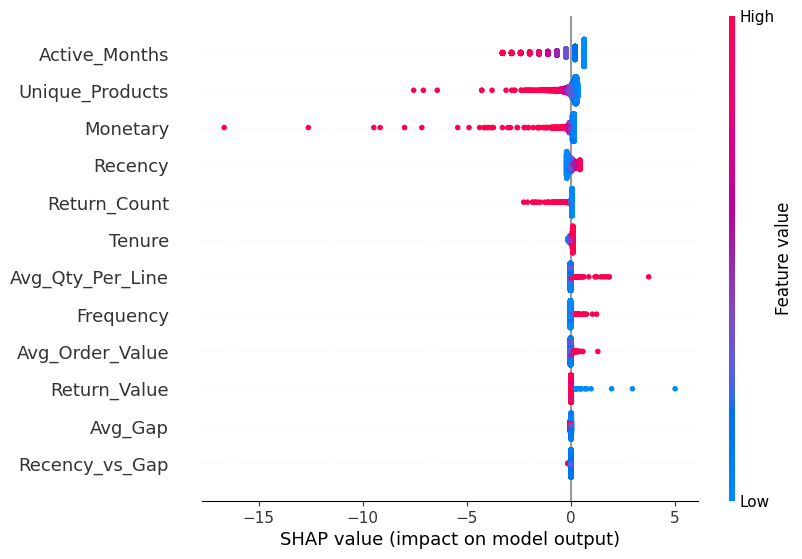

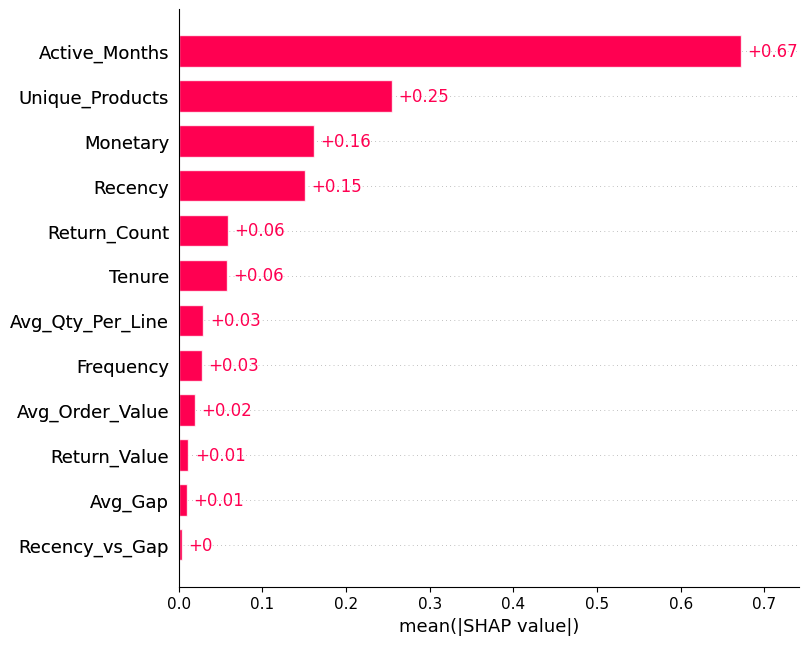

In [ ]:
# Definition (English): SHAP (SHapley Additive exPlanations) tells how much each feature pushed a single prediction
# up or down compared to the average prediction.
# Hinglish: Model ne kisi customer ko “risky” kyun bola, ye SHAP batata hai. Har feature
# ka hisaab: kisne risk badhaya, kisne kam kiya.
# SHAP se dekhna ki har feature ne churn prediction ko kitna upar ya neeche kiya

import shap

Xs = pd.DataFrame(final[0].transform(X), columns=X.columns)
explainer = shap.LinearExplainer(final[-1], Xs)
sv = explainer(Xs)

shap.plots.beeswarm(sv, max_display=12)
shap.plots.bar(sv, max_display=12)
#Business meaning: churn sabse zyada is baat se decide hota hai ki customer kitne alag mahino
# mein aaya. Ek-do mahine ke baad gayab hone wale customers ko jaldi follow-up karna chahiye.

Customer: 15749.0 | Risk: 0.857 | Asli label (1 = churned): 1


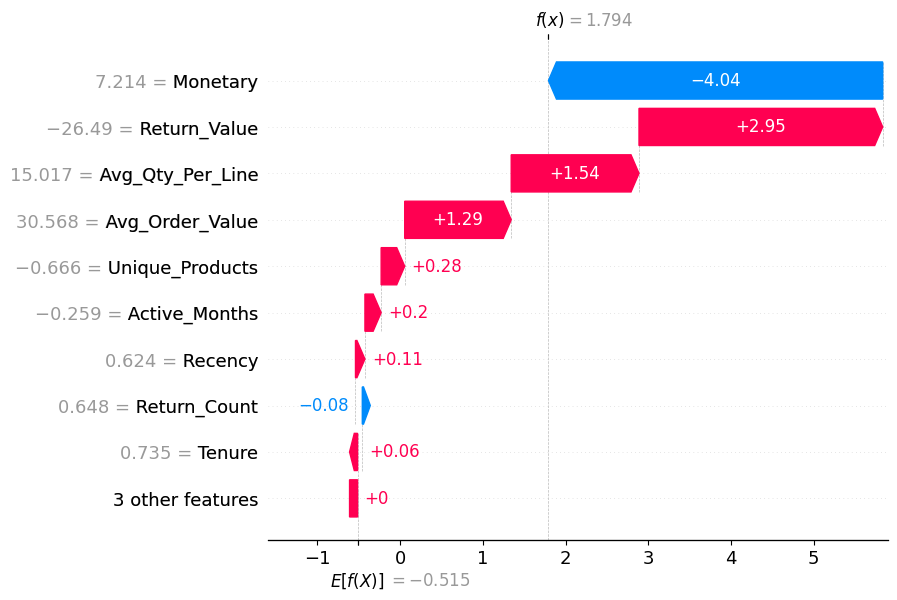

In [ ]:
# Top 30 risky customers mein se sabse zyada Monetary wala customer chunke uska SHAP waterfall dekhna

risk = pd.Series(final.predict_proba(X)[:, 1], index=X.index)
cid = X.loc[risk.nlargest(30).index, 'Monetary'].idxmax()
pos = X.index.get_loc(cid)

print("Customer:", cid, "| Risk:", round(risk[cid], 3), "| Asli label (1 = churned):", y[cid])
shap.plots.waterfall(sv[pos])

In [ ]:
# Data ke end par sabhi customers ke features banake churn risk nikalna aur high-value risky customers ki list banana

def make_features(data, returns, cut):
    d = data[data['InvoiceDate'] < cut].copy()
    d['Month'] = d['InvoiceDate'].dt.to_period('M')
    o = d.groupby(['CustomerID', 'InvoiceNo']).agg(Date=('InvoiceDate', 'min')).reset_index().sort_values(['CustomerID', 'Date'])
    o['Gap'] = o.groupby('CustomerID')['Date'].diff().dt.total_seconds() / 86400
    f = d.groupby('CustomerID').agg(
        Recency=('InvoiceDate', lambda x: (cut - x.max()).days),
        Tenure=('InvoiceDate', lambda x: (cut - x.min()).days),
        Frequency=('InvoiceNo', 'nunique'),
        Monetary=('Revenue', 'sum'),
        Unique_Products=('StockCode', 'nunique'),
        Active_Months=('Month', 'nunique'),
        Avg_Qty_Per_Line=('Quantity', 'mean'))
    f['Avg_Order_Value'] = f['Monetary'] / f['Frequency']
    f['Avg_Gap'] = o.groupby('CustomerID')['Gap'].mean()
    f['Avg_Gap'] = f['Avg_Gap'].fillna(f['Tenure'])
    f['Recency_vs_Gap'] = f['Recency'] / (f['Avg_Gap'] + 1)
    r = returns[returns['InvoiceDate'] < cut].groupby('CustomerID')['Revenue'].agg(Return_Count='size', Return_Value='sum')
    f = f.join(r).fillna({'Return_Count': 0, 'Return_Value': 0})
    return f[X.columns]

live = make_features(df_clean, df_returns, pd.Timestamp('2011-12-10'))
live['Churn_Risk'] = final.predict_proba(live[X.columns])[:, 1]

active = live[live['Recency'] <= 90]
action = active[active['Churn_Risk'] >= 0.6].sort_values('Monetary', ascending=False)

print("Customers:", len(live), "| Active (last 90 din):", len(active), "| High risk (>=60%):", len(action))
print(action[['Recency', 'Frequency', 'Monetary', 'Active_Months', 'Churn_Risk']].head(20).round(2).to_string())

Customers: 4336 | Active (last 90 din): 2888 | High risk (>=60%): 34
            Recency  Frequency  Monetary  Active_Months  Churn_Risk
CustomerID                                                         
18251.0          87          1   4314.72              1        0.68
15195.0           2          1   3861.00              1        0.80
16308.0          37          4   2560.00              4        0.68
17846.0          85          1   2033.10              1        0.61
16986.0          29          2   1873.20              1        0.62
14887.0          79          1   1862.00              1        0.63
14212.0          89          1   1070.48              1        0.62
12497.0          81          1   1043.10              1        0.60
18194.0          82          1    973.84              1        0.61
13689.0          63          1    910.00              1        0.60
17640.0          86          1    621.66              1        0.61
14609.0          72          4    601.56       

In [ ]:
# Phase 5 shuru: AI Business Intelligence
# Ab tak ke computed numbers se report.md file apne aap banana

top_prod = prod.sort_values('Revenue', ascending=False).iloc[0]

lines = [
    "# Online Retail Project Report",
    "",
    "## Data cleaning",
    f"- Reversal pairs removed: {len(rev)} (revenue £{rev['Revenue_sale'].sum():,.2f})",
    f"- Gross sales after cleaning: £{gross:,.2f}",
    f"- Returns: £{abs(returns):,.2f} ({abs(returns) / gross * 100:.2f}% of gross)",
    "",
    "## Sales",
    f"- Top country: {country.index[0]} ({country['Share_%'].iloc[0]:.1f}% of revenue)",
    f"- Peak month: {monthly['Revenue'].idxmax()} (£{monthly['Revenue'].max():,.2f})",
    f"- Top product: {top_prod['Description']} (£{top_prod['Revenue']:,.2f})",
    "",
    "## Churn",
    "- Definition: no purchase within 90 days after 2011-09-11",
    f"- Churn rate: {labels['Churned'].mean() * 100:.1f}% of {len(labels):,} customers",
    f"- High-risk active customers today: {len(action)}"]

with open('report.md', 'w') as fh:
    fh.write("\n".join(lines))

print("\n".join(lines))

# Online Retail Project Report

## Data cleaning
- Reversal pairs removed: 454 (revenue £325,373.60)
- Gross sales after cleaning: £8,586,034.30
- Returns: £325,378.17 (3.79% of gross)

## Sales
- Top country: United Kingdom (81.5% of revenue)
- Peak month: 2011-11 (£1,155,040.83)
- Top product: REGENCY CAKESTAND 3 TIER (£141,257.95)

## Churn
- Definition: no purchase within 90 days after 2011-09-11
- Churn rate: 43.0% of 3,368 customers
- High-risk active customers today: 34


In [ ]:
# Flagged invoices ko rule se label dena: Genuine bulk, Suspicious ya Needs review

f = flagged.copy()
f['InvoiceNo'] = f['InvoiceNo'].astype(str)

line_count = df_clean.assign(InvoiceNo=df_clean['InvoiceNo'].astype(str)).groupby('InvoiceNo').size().rename('Lines')
cancelled = pairs.assign(InvoiceNo=pairs['InvoiceNo_sale'].astype(str)).groupby('InvoiceNo')['Revenue_sale'].sum().rename('Cancelled_Revenue')

f = f.join(line_count, on='InvoiceNo').join(cancelled, on='InvoiceNo')
f['Cancelled_Revenue'] = f['Cancelled_Revenue'].fillna(0)
f['Cancel_Share'] = f['Cancelled_Revenue'] / f['Revenue']
f['Customer_Orders'] = f['CustomerID'].map(rfm_clean['Frequency'])

def label_invoice(r):
    if r['Cancel_Share'] >= 0.5:
        return 'Suspicious'
    if r['Customer_Orders'] >= 10 and r['Cancel_Share'] < 0.2:
        return 'Genuine bulk'
    return 'Needs review'

f['Label'] = f.apply(label_invoice, axis=1)

print(f.groupby('Label')['Revenue'].agg(['count', 'sum']).round(2))
print(f[f['Label'] != 'Genuine bulk'].sort_values('Revenue', ascending=False).head(10).round(2).to_string(index=False))

              count         sum
Label                          
Genuine bulk    827  2346947.20
Needs review    611   987294.54
Suspicious       16    52167.06
InvoiceNo  CustomerID  Revenue  Lines  Cancelled_Revenue  Cancel_Share  Customer_Orders        Label
   550461     15749.0 21535.90      5               0.00          0.00                3 Needs review
   540815     15749.0 15160.90      3           15160.90          1.00                3   Suspicious
   552978     12590.0  9341.26     67               0.00          0.00                2 Needs review
   581105     16000.0  8345.20      7               0.00          0.00                3 Needs review
   540818     15749.0  7837.50      2            4522.50          0.58                3   Suspicious
   570097     16029.0  7630.56      8            7630.56          1.00               61   Suspicious
   574740     12357.0  6207.67    131               0.00          0.00                1 Needs review
   556415     12409.0  6207.08  

In [ ]:
# 16 Suspicious invoices ka cancel gap (din mein) dekhna taaki rule ko theek kar sakein

gap = pairs.assign(InvoiceNo=pairs['InvoiceNo_sale'].astype(str)).groupby('InvoiceNo')['gap_min'].min().div(1440).rename('Gap_Days')

s = f[f['Label'] == 'Suspicious'].join(gap, on='InvoiceNo')
print(s[['InvoiceNo', 'CustomerID', 'Revenue', 'Cancel_Share', 'Customer_Orders', 'Gap_Days']].sort_values('Revenue', ascending=False).round(2).to_string(index=False))

InvoiceNo  CustomerID  Revenue  Cancel_Share  Customer_Orders  Gap_Days
   540815     15749.0 15160.90          1.00                3     97.01
   540818     15749.0  7837.50          0.58                3     97.01
   570097     16029.0  7630.56          1.00               61      3.96
   571255     12454.0  3528.34          1.00                1      2.91
   558523     17949.0  2231.30          1.00               44     48.18
   574319     15482.0  1915.60          0.73               11      0.96
   549468     17940.0  1867.86          1.00               10     46.13
   551259     17949.0  1642.50          1.00               44    117.21
   570467     12607.0  1579.51          1.00                1      2.01
   540275     13680.0  1520.11          1.00                4      0.95
   539109     16013.0  1491.00          1.00               47      0.94
   576623     12748.0  1301.00          1.00              207      0.91
   539444     14146.0  1241.43          1.00                5   

In [ ]:
# Cancel ke gap ke hisaab se rule theek karke final labels dena

f = f.drop(columns='Gap_Days', errors='ignore').join(gap, on='InvoiceNo')

def final_label(r):
    if r['Cancel_Share'] >= 0.5 and r['Gap_Days'] <= 7:
        return 'Cancelled quickly'
    if r['Cancel_Share'] >= 0.5:
        return 'Returned later'
    if r['Customer_Orders'] >= 10 and r['Cancel_Share'] < 0.2:
        return 'Genuine bulk'
    return 'Needs review'

f['Label'] = f.apply(final_label, axis=1)
print(f.groupby('Label')['Revenue'].agg(['count', 'sum']).round(2))


                   count         sum
Label                               
Cancelled quickly      8    20099.07
Genuine bulk         827  2346947.20
Needs review         611   987294.54
Returned later         8    32067.99


In [ ]:
# Har segment ka size, revenue, churn rate aur ek recommended action ek table mein

seg = seg_table(rfm_segments(df_clean))
seg['Churn_Rate_%'] = (chk.groupby('Segment', observed=True)['Churned'].mean() * 100).round(1)

actions = {
    'Champions': 'Reward with early access and perks, win back churned ones first',
    'Loyal': 'Upsell and bundle offers to move them to Champions',
    'Potential Loyalist': 'Push a repeat purchase within 30 days',
    'At Risk': 'Win-back offer, personal follow-up for high spenders',
    'Hibernating': 'Low-cost reactivation email, stop if no response'}

seg['Action'] = pd.Series(actions)
print(seg.to_string())

                    Customers     Revenue  Share_%  Churn_Rate_%                                                           Action
Segment                                                                                                                          
Hibernating              1310   366216.66      4.3          65.3                 Low-cost reactivation email, stop if no response
At Risk                   766   451326.64      5.3          54.9             Win-back offer, personal follow-up for high spenders
Potential Loyalist        671   682285.31      7.9          42.6                            Push a repeat purchase within 30 days
Loyal                     660  1043384.98     12.2          29.8               Upsell and bundle offers to move them to Champions
Champions                 929  6042820.71     70.4          11.5  Reward with early access and perks, win back churned ones first


In [ ]:
# Phase 6 shuru: dashboard aur GitHub
# Dashboard aur GitHub ke liye final tables outputs folder mein CSV ke roop mein save karna

import os

os.makedirs('outputs', exist_ok=True)

seg.to_csv('outputs/segments.csv')
action.to_csv('outputs/high_risk_customers.csv')
f.to_csv('outputs/flagged_invoices.csv', index=False)
monthly.to_csv('outputs/monthly.csv')
country.to_csv('outputs/country.csv')
prod.sort_values('Revenue', ascending=False).head(50).to_csv('outputs/top_products.csv')

print(os.listdir('outputs'))

['segments.csv', 'monthly.csv', 'high_risk_customers.csv', 'top_products.csv', 'country.csv', 'flagged_invoices.csv']


In [ ]:
# SQL Server mein import karne ke liye clean sales aur returns data CSV mein save karna

df_clean.to_csv('outputs/clean_sales.csv', index=False)
df_returns.to_csv('outputs/returns.csv', index=False)

print(df_clean.shape, df_returns.shape)

(397430, 9) (8451, 9)


In [ ]:
# Clean sales aur returns CSV ko apne computer pe download karna (Colab ke liye)

from google.colab import files

files.download('outputs/clean_sales.csv')
files.download('outputs/returns.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Reversal pairs SQL mein dhundne ke liye raw data (cancel invoices ke saath) CSV mein save karna

df.to_csv('outputs/raw_sales.csv', index=False)

print(df.shape)

(541909, 9)


In [ ]:
# Notebook mein available DataFrames aur unka size check karna
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape)

_ (10, 3)
__ (5, 3)
___ (1, 5)
df (541909, 9)
zero_price (2515, 9)
sales (397924, 13)
monthly_sales (13, 2)
monthly_metrics (13, 4)
customer_revenue (10, 4)
rfm_data (397884, 9)
rfm (4338, 9)
_13 (5, 4)
_14 (10, 7)
_15 (10, 9)
segment_analysis (5, 4)
_16 (5, 4)
_17 (5, 4)
at_risk_top10 (10, 9)
_18 (10, 4)
_19 (1, 5)
_20 (5, 3)
invoice_data (18532, 3)
anomalies (1466, 3)
_21 (10, 3)
c (4, 9)
d (406829, 10)
cancels (8905, 12)
pairs (2860, 13)
labels (3368, 2)
summary (5, 3)
rev (454, 13)
raw (541909, 9)
base (397884, 9)
df_clean (397430, 9)
all_cancels (8905, 9)
df_returns (8451, 9)
rfm_clean (4336, 3)
inv (18464, 3)
flagged (1454, 3)
top (10, 3)
ev (10, 4)
p (3658, 7)
orders (18464, 4)
out (10, 10)
before (236075, 9)
after (161355, 9)
non_prod (1522, 9)
df_prod (395908, 9)
prod (3658, 6)
monthly (13, 3)
country (37, 6)
cust_country (4344, 3)
top_cust (37, 2)
check (37, 9)
cp (6500, 5)
top3 (15, 5)
cust (4336, 3)
rfm_cut (3368, 8)
chk (3368, 9)
b (236075, 10)
orders_b (11865, 5)
feat (33

In [ ]:
# Existing ML features aur labels ke columns check karna
print("FEAT COLUMNS:", feat.columns.tolist())
print("\nLABELS:")
print(labels.head())
print("\nX COLUMNS:", X.columns.tolist())
print("\nX TRAIN:", X_train.shape)
print("X TEST:", X_test.shape)

FEAT COLUMNS: ['Recency', 'Tenure', 'Frequency', 'Monetary', 'Unique_Products', 'Active_Months', 'Avg_Qty_Per_Line', 'Avg_Order_Value', 'Avg_Gap', 'Recency_vs_Gap', 'Return_Count', 'Return_Value', 'Churned']

LABELS:
   CustomerID  Churned
0     17850.0        1
1     13047.0        0
2     12583.0        0
3     13748.0        1
4     15100.0        1

X COLUMNS: ['Recency', 'Tenure', 'Frequency', 'Monetary', 'Unique_Products', 'Active_Months', 'Avg_Qty_Per_Line', 'Avg_Order_Value', 'Avg_Gap', 'Recency_vs_Gap', 'Return_Count', 'Return_Value']

X TRAIN: (2526, 12)
X TEST: (842, 12)


In [ ]:
# Churned aur Non-Churned customers ka distribution check karna

print("Class Distribution:")
print(labels['Churned'].value_counts())

print("\nClass Percentage:")
print(labels['Churned'].value_counts(normalize=True) * 100)

Class Distribution:
Churned
0    1920
1    1448
Name: count, dtype: int64

Class Percentage:
Churned
0    57.007126
1    42.992874
Name: proportion, dtype: float64


Machine Leaning Model train

In [ ]:
# Features scale karke Logistic Regression ko dobara train karna

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LogisticRegression(max_iter=2000, random_state=42)

lr_model.fit(X_train_scaled, y_train)

print("Model Trained Successfully!")

Model Trained Successfully!


In [ ]:
# Model ki predictions aur performance evaluate karna

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = lr_model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


# Business Insights
# - Model ne 362 actual churned customers mein se 232 identify kiye.
# - 130 churned customers identify nahi ho paaye.
# - 152 non-churned customers ko incorrectly churn predict kiya.
# - Churn Recall 64% hai, jo customer retention analysis ke liye important metric hai.
# 4. Model Conclusion
# Logistic Regression ne 66.51% accuracy achieve ki. Model customer churn predict karne mein moderately effective hai, lekin abhi improvement ki scope hai.

Accuracy: 0.665083135391924

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.68      0.70       480
           1       0.60      0.64      0.62       362

    accuracy                           0.67       842
   macro avg       0.66      0.66      0.66       842
weighted avg       0.67      0.67      0.67       842


Confusion Matrix:
[[328 152]
 [130 232]]


In [ ]:
# Random Forest model train aur evaluate karna

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 0.6520190023752969

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.71      0.70       480
           1       0.60      0.57      0.59       362

    accuracy                           0.65       842
   macro avg       0.64      0.64      0.64       842
weighted avg       0.65      0.65      0.65       842



In [ ]:
# Random Forest ke important features identify karna

import pandas as pd

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

display(feature_importance)

,Feature,Importance
3,Monetary,0.127131
4,Unique_Products,0.115095
6,Avg_Qty_Per_Line,0.104752
7,Avg_Order_Value,0.103802
8,Avg_Gap,0.098809
0,Recency,0.093714
9,Recency_vs_Gap,0.092950
1,Tenure,0.080684
5,Active_Months,0.072844
2,Frequency,0.055555


In [ ]:
# SHAP kya-kya batata hai?
# SHAP se hum 3 important analyses kar sakte hain:
# 1. Global Explanation: Overall model mein kaunse features important hain?
# 2. Local Explanation: Kisi particular customer ko churn predict kyun kiya?
# 3. Feature Impact: Kaunsa feature prediction ko churn ki taraf aur kaunsa non-churn ki taraf influence kar raha hai?

In [ ]:
# Feature engineering mein use hue data ka date range check karna

print("Before Data:")
print("Start:", before['InvoiceDate'].min())
print("End:", before['InvoiceDate'].max())

print("\nFull Clean Data:")
print("Start:", df_clean['InvoiceDate'].min())
print("End:", df_clean['InvoiceDate'].max())

print("\nFeature Data Shape:", feat.shape)

Before Data:
Start: 2010-12-01 08:26:00
End: 2011-09-09 15:53:00

Full Clean Data:
Start: 2010-12-01 08:26:00
End: 2011-12-09 12:50:00

Feature Data Shape: (3368, 13)


In [ ]:
# Feature dataset mein missing values aur basic statistics check karna

display(feat.describe().T)

,count,mean,std,min,25%,50%,75%,max
Recency,3368.0,95.079276,80.024855,1.000000,26.000000,74.000000,152.000000,283.000000
Tenure,3368.0,182.919537,80.445982,1.000000,123.000000,193.000000,265.000000,283.000000
Frequency,3368.0,3.522862,5.754151,1.000000,1.000000,2.000000,4.000000,130.000000
Monetary,3368.0,1579.153774,5954.955663,2.900000,264.445000,563.265000,1380.330000,178302.620000
Unique_Products,3368.0,49.938242,67.519426,1.000000,14.000000,29.000000,63.000000,1230.000000
Active_Months,3368.0,2.533551,2.060721,1.000000,1.000000,2.000000,3.000000,10.000000
Avg_Qty_Per_Line,3368.0,22.635536,118.557976,1.000000,5.931171,9.725705,14.569196,4300.000000
Avg_Order_Value,3368.0,371.870842,473.537769,2.900000,169.023000,283.620000,415.226250,14844.766667
Avg_Gap,3368.0,93.762595,75.968329,0.000000,35.030035,67.085851,141.307812,283.000000
Recency_vs_Gap,3368.0,3.691386,19.797235,0.005343,0.596637,0.991803,1.053637,282.803609


In [ ]:
# Feature dataset mein original CustomerID aur target ka alignment check karna

print("Feature Index:", feat.index[:5].tolist())
print("Label Index:", labels.index[:5].tolist())

print("\nCustomer count:", feat.shape[0])
print("Label count:", labels.shape[0])

print("\nFeature and Label Churn Match:")
print((feat['Churned'].values == labels['Churned'].values).all())

Feature Index: [12347.0, 12348.0, 12350.0, 12352.0, 12353.0]
Label Index: [0, 1, 2, 3, 4]

Customer count: 3368
Label count: 3368

Feature and Label Churn Match:
False


In [ ]:
# CustomerID ke basis par actual churn labels verify karna

check = feat[['Churned']].merge(
    labels,
    left_index=True,
    right_on='CustomerID',
    how='inner'
)

print("Matched Customers:", len(check))

print("Churn Label Match:",
      (check['Churned_x'] == check['Churned_y']).all())

print("\nMismatch Count:",
      (check['Churned_x'] != check['Churned_y']).sum())

Matched Customers: 3368
Churn Label Match: True

Mismatch Count: 0


In [ ]:
# Feature dataset aur before dataset ke customer records verify karna

print("Before Customers:", before['CustomerID'].nunique())
print("Feature Customers:", feat.shape[0])

print("\nFeature Customers Available Before Cutoff:",
      feat.index.isin(before['CustomerID'].unique()).all())

print("\nFeature Customer Date Limit:")
print("Before Data Last Date:", before['InvoiceDate'].max())
print("Cutoff Date:", cutoff)

Before Customers: 3368
Feature Customers: 3368

Feature Customers Available Before Cutoff: True

Feature Customer Date Limit:
Before Data Last Date: 2011-09-09 15:53:00
Cutoff Date: 2011-09-11 00:00:00


In [ ]:
# Hinglish: Google Drive ko Colab se connect kar rahe hain
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Hinglish: Drive mein Online Retail project ka folder bana rahe hain
import os

project_path = '/content/drive/MyDrive/Online_Retail_Project'
os.makedirs(project_path, exist_ok=True)

print("Project folder ready:", project_path)

Project folder ready: /content/drive/MyDrive/Online_Retail_Project


In [ ]:
# Hinglish: Important project variables ko Drive mein save kar rahe hain
import joblib

checkpoint = {
    'df_clean': df_clean,
    'before': before,
    'feat': feat,
    'labels': labels
}

joblib.dump(checkpoint, project_path + '/checkpoint.pkl')

print("Checkpoint successfully saved!")

Checkpoint successfully saved!


In [ ]:
# Hinglish: Drive se saved project variables load kar rahe hain
import joblib

checkpoint = joblib.load(project_path + '/checkpoint.pkl')

df_clean = checkpoint['df_clean']
before = checkpoint['before']
feat = checkpoint['feat']
labels = checkpoint['labels']

print("All project variables restored!")
print("Clean Data:", df_clean.shape)
print("Features:", feat.shape)
print("Labels:", labels.shape)

All project variables restored!
Clean Data: (397430, 9)
Features: (3368, 13)
Labels: (3368, 2)


In [ ]:
# Hinglish: Check kar rahe hain trained models aur scaler available hain ya nahi
for var in ['lr_model', 'rf_model', 'scaler']:
    print(var, "Available" if var in globals() else "Not Available")

lr_model Available
rf_model Available
scaler Available


In [ ]:
# Hinglish: Trained models aur scaler ko checkpoint mein save kar rahe hain
checkpoint.update({
    'lr_model': lr_model,
    'rf_model': rf_model,
    'scaler': scaler
})

joblib.dump(checkpoint, project_path + '/checkpoint.pkl')

print("Models and scaler saved successfully!")

Models and scaler saved successfully!


In [ ]:
# Hinglish: Historical aur full dataset ke customer orders compare kar rahe hain

before_counts = before.groupby('CustomerID').size()
full_counts = df_clean.groupby('CustomerID').size()

comparison = pd.DataFrame({
    'Before_Count': before_counts,
    'Full_Count': full_counts
})

print("Customers with additional future transactions:",
      (comparison['Full_Count'] > comparison['Before_Count']).sum())

Customers with additional future transactions: 1920


In [ ]:
# Hinglish: Existing customer features ka sample dekh rahe hain
display(feat.head(5))

,Recency,Tenure,Frequency,Monetary,Unique_Products,Active_Months,Avg_Qty_Per_Line,Avg_Order_Value,Avg_Gap,Recency_vs_Gap,Return_Count,Return_Value,Churned
CustomerID,,,,,,,,,,,,,
12347.0,39,277,5,2790.86,82,5,12.822581,558.172000,59.435938,0.645311,0.0,0.00,0
12348.0,158,268,3,1487.24,22,3,75.857143,495.746667,54.825694,2.830238,0.0,0.00,0
12350.0,220,220,1,334.40,17,1,11.588235,334.400000,220.000000,0.995475,0.0,0.00,1
12352.0,172,206,5,1561.81,26,2,6.684211,312.362000,8.537326,18.034404,10.0,-960.63,0
12353.0,114,114,1,89.00,4,1,5.000000,89.000000,114.000000,0.991304,0.0,0.00,1


In [ ]:
# Hinglish: Historical data se Recency aur Tenure dobara calculate karke compare kar rahe hain

check = before.groupby('CustomerID')['InvoiceDate'].agg(
    First_Purchase='min',
    Last_Purchase='max'
)

check['Recency_Check'] = (cutoff - check['Last_Purchase']).dt.days
check['Tenure_Check'] = (cutoff - check['First_Purchase']).dt.days

check['Recency_Match'] = check['Recency_Check'] == feat['Recency']
check['Tenure_Match'] = check['Tenure_Check'] == feat['Tenure']

print("Recency mismatches:", (~check['Recency_Match']).sum())
print("Tenure mismatches:", (~check['Tenure_Match']).sum())

Recency mismatches: 0
Tenure mismatches: 0


In [ ]:
# Hinglish: Historical data se unique invoices count karke Frequency verify kar rahe hain

frequency_check = before.groupby('CustomerID')['InvoiceNo'].nunique()

print("Frequency mismatches:",
      (frequency_check != feat['Frequency']).sum())

Frequency mismatches: 0


In [ ]:
# Hinglish: NumPy import karke Monetary feature verify kar rahe hain
import numpy as np

print("Monetary mismatches:",
      (~np.isclose(monetary_check, feat['Monetary'])).sum())

Monetary mismatches: 0


In [ ]:
# Hinglish: Historical data se unique products count verify kar rahe hain
products_check = before.groupby('CustomerID')['StockCode'].nunique()

print("Unique Products mismatches:",
      (products_check != feat['Unique_Products']).sum())


Unique Products mismatches: 0


In [ ]:
# Hinglish: Historical transactions se active months verify kar rahe hain
months_check = (
    before.assign(Month=before['InvoiceDate'].dt.to_period('M'))
    .groupby('CustomerID')['Month']
    .nunique()
)

print("Active Months mismatches:",
      (months_check != feat['Active_Months']).sum())

Active Months mismatches: 0


In [ ]:
# Hinglish: Historical data se average quantity per line verify kar rahe hain
qty_check = before.groupby('CustomerID')['Quantity'].mean()

print("Avg Qty Per Line mismatches:",
      (~np.isclose(qty_check, feat['Avg_Qty_Per_Line'])).sum())

Avg Qty Per Line mismatches: 0


In [ ]:
# Hinglish: Historical data se average order value verify kar rahe hain
order_value_check = (
    before.assign(Sales=before['Quantity'] * before['UnitPrice'])
    .groupby(['CustomerID', 'InvoiceNo'])['Sales']
    .sum()
    .groupby('CustomerID')
    .mean()
)

print("Avg Order Value mismatches:",
      (~np.isclose(order_value_check, feat['Avg_Order_Value'])).sum())

Avg Order Value mismatches: 0


In [ ]:
# Hinglish: Historical data se consecutive orders ke average gap ko verify kar rahe hain
invoice_dates = (
    before.groupby(['CustomerID', 'InvoiceNo'])['InvoiceDate']
    .min()
    .reset_index()
    .sort_values(['CustomerID', 'InvoiceDate'])
)

invoice_dates['Gap'] = (
    invoice_dates.groupby('CustomerID')['InvoiceDate']
    .diff().dt.total_seconds() / 86400
)

gap_check = invoice_dates.groupby('CustomerID')['Gap'].mean()

print("Avg Gap mismatches:",
      (~np.isclose(gap_check, feat['Avg_Gap'], equal_nan=True)).sum())

Avg Gap mismatches: 1363


In [ ]:
# Hinglish: Existing aur recalculated Avg_Gap ki values compare kar rahe hain
gap_comparison = pd.DataFrame({
    'Existing': feat['Avg_Gap'],
    'Recalculated': gap_check
})

gap_comparison['Difference'] = (
    gap_comparison['Existing'] - gap_comparison['Recalculated']
)

mismatch = ~np.isclose(
    gap_comparison['Existing'],
    gap_comparison['Recalculated'],
    equal_nan=True
)

print("Mismatch count:", mismatch.sum())
display(gap_comparison[mismatch].head(10))

Mismatch count: 1363


,Existing,Recalculated,Difference
CustomerID,,,
12350.0,220.0,NaN,NaN
12353.0,114.0,NaN,NaN
12354.0,142.0,NaN,NaN
12355.0,124.0,NaN,NaN
12358.0,60.0,NaN,NaN
12361.0,197.0,NaN,NaN
12364.0,22.0,NaN,NaN
12373.0,221.0,NaN,NaN
12375.0,8.0,NaN,NaN


In [ ]:
# Hinglish: Single-invoice customers count kar rahe hain
invoice_count = before.groupby('CustomerID')['InvoiceNo'].nunique()

print("Single invoice customers:", (invoice_count == 1).sum())
print("Multiple invoice customers:", (invoice_count > 1).sum())

Single invoice customers: 1363
Multiple invoice customers: 2005


In [ ]:
# Hinglish: Sirf multiple-invoice customers ka Avg_Gap verify kar rahe hain
multiple_customers = invoice_count[invoice_count > 1].index

gap_match = np.isclose(
    gap_comparison.loc[multiple_customers, 'Existing'],
    gap_comparison.loc[multiple_customers, 'Recalculated'],
    equal_nan=True
)

print("Multiple invoice customers:", len(multiple_customers))
print("Avg Gap mismatches:", (~gap_match).sum())

Multiple invoice customers: 2005
Avg Gap mismatches: 0


In [ ]:
# Hinglish: Recency aur Avg_Gap ka ratio verify kar rahe hain
ratio_check = feat['Recency'] / feat['Avg_Gap']

print("Recency_vs_Gap mismatches:",
      (~np.isclose(ratio_check, feat['Recency_vs_Gap'])).sum())

Recency_vs_Gap mismatches: 3368


In [ ]:
# Hinglish: Existing feature ko correct formula se verify kar rahe hain
ratio_check = feat['Recency'] / (feat['Avg_Gap'] + 1)

print("Recency_vs_Gap mismatches:",
      (~np.isclose(ratio_check, feat['Recency_vs_Gap'])).sum())

Recency_vs_Gap mismatches: 0


In [ ]:
# Hinglish: Historical data mein negative quantity wali return lines count kar rahe hain
return_count_check = (
    before[before['Quantity'] < 0]
    .groupby('CustomerID')
    .size()
    .reindex(feat.index, fill_value=0)
)

print("Return_Count mismatches:",
      (return_count_check != feat['Return_Count']).sum())

Return_Count mismatches: 1135


In [ ]:
# Hinglish: Existing aur negative-quantity rows ke counts compare kar rahe hain
return_comparison = pd.DataFrame({
    'Existing': feat['Return_Count'],
    'Negative_Qty_Rows': return_count_check
})

return_comparison['Difference'] = (
    return_comparison['Existing'] - return_comparison['Negative_Qty_Rows']
)

display(return_comparison[
    return_comparison['Existing'] != return_comparison['Negative_Qty_Rows']
].head(10))

,Existing,Negative_Qty_Rows,Difference
CustomerID,,,
12352.0,10.0,0,10.0
12359.0,2.0,0,2.0
12362.0,5.0,0,5.0
12365.0,1.0,0,1.0
12379.0,1.0,0,1.0
12381.0,4.0,0,4.0
12383.0,1.0,0,1.0
12395.0,2.0,0,2.0
12406.0,3.0,0,3.0


In [ ]:
# Hinglish: Full dataset ke return counts ko existing Return_Count se compare kar rahe hain
full_return_count = (
    df_clean[df_clean['Quantity'] < 0]
    .groupby('CustomerID')
    .size()
    .reindex(feat.index, fill_value=0)
)

print("Full dataset mismatches:",
      (full_return_count != feat['Return_Count']).sum())

Full dataset mismatches: 1135


In [ ]:
# Hinglish: Negative quantity wale unique invoices count karke compare kar rahe hain
return_invoice_check = (
    before[before['Quantity'] < 0]
    .groupby('CustomerID')['InvoiceNo']
    .nunique()
    .reindex(feat.index, fill_value=0)
)

print("Unique return invoice mismatches:",
      (return_invoice_check != feat['Return_Count']).sum())

Unique return invoice mismatches: 1135


In [ ]:
# Hinglish: Full dataset ke unique return invoices compare kar rahe hain
full_return_invoices = (
    df_clean[df_clean['Quantity'] < 0]
    .groupby('CustomerID')['InvoiceNo']
    .nunique()
    .reindex(feat.index, fill_value=0)
)

print("Full unique return invoice mismatches:",
      (full_return_invoices != feat['Return_Count']).sum())

Full unique return invoice mismatches: 1135


In [ ]:
# Hinglish: C se start hone wale cancelled invoices ka count compare kar rahe hain
cancel_before = before[before['InvoiceNo'].astype(str).str.startswith('C')]

cancel_rows = (
    cancel_before.groupby('CustomerID')
    .size()
    .reindex(feat.index, fill_value=0)
)

cancel_invoices = (
    cancel_before.groupby('CustomerID')['InvoiceNo']
    .nunique()
    .reindex(feat.index, fill_value=0)
)

print("Cancelled invoice row mismatches:",
      (cancel_rows != feat['Return_Count']).sum())

print("Cancelled unique invoice mismatches:",
      (cancel_invoices != feat['Return_Count']).sum())

Cancelled invoice row mismatches: 1135
Cancelled unique invoice mismatches: 1135


In [ ]:
# Definition: Data Leakage tab hota hai jab Machine Learning model ko training ke time aisa data mil jata hai jo actual prediction karte waqt available nahi hona chahiye.
# Example: Agar hum predict kar rahe hain ki customer agle 90 days mein churn hoga ya nahi, aur galti se uske future purchase data ko input feature mein use kar lete hain, toh ise Data Leakage kehte hain.

# Hinglish: Return_Count aur actual return entries ke sample compare kar rahe hain
comparison = pd.DataFrame({
    'Feature_Return_Count': feat['Return_Count'],
    'Cancelled_Invoices': cancel_invoices,
    'Negative_Qty_Rows': (
        before[before['Quantity'] < 0]
        .groupby('CustomerID').size()
        .reindex(feat.index, fill_value=0)
    )
})

print(comparison[comparison['Feature_Return_Count'] != comparison['Cancelled_Invoices']].head(10))

            Feature_Return_Count  Cancelled_Invoices  Negative_Qty_Rows
CustomerID                                                             
12352.0                     10.0                   0                  0
12359.0                      2.0                   0                  0
12362.0                      5.0                   0                  0
12365.0                      1.0                   0                  0
12379.0                      1.0                   0                  0
12381.0                      4.0                   0                  0
12383.0                      1.0                   0                  0
12395.0                      2.0                   0                  0
12406.0                      3.0                   0                  0
12408.0                      7.0                   0                  0
